# De Franceschi Mohamed
#### M2-IM

# HW1 : PAC et PAC agnostique avec des classifieurs à seuil

On veut apprendre une règle simple : $f_\theta(x) = 1$ si $x > \theta$, sinon $0$, avec $x$ tiré au hasard entre 0 et 1. L'algorithme ne connaît pas $\theta$. Il voit seulement des exemples $(x, y)$ et doit retrouver un bon seuil.

On compare deux situations. Dans le cas réalisable (PAC), les labels sont toujours justes. Dans le cas agnostique, chaque label est faux avec une probabilité $\eta$.

Tout est codé avec NumPy, sans bibliothèque de machine learning.

## 0. Paramètres

| Paramètre | Valeur | Rôle |
|---|---|---|
| $\theta$ | 0,37 | le vrai seuil (choix arbitraire, loin de 0,5 et des bords) |
| $\varepsilon$ | 0,05 | l'erreur qu'on tolère |
| $\eta$ | 0,10 | proportion de labels faux dans le cas agnostique |
| $m$ | 5, 10, 20, 50, 100, 200 | tailles d'entraînement demandées |
| répétitions | 1000 | nombre d'essais pour estimer une probabilité |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # graine fixe pour des résultats reproductibles

THETA = 0.37
EPS = 0.05
ETA = 0.1
M_VALUES = [5, 10, 20, 50, 100, 200]
N_REPS = 1000
N_TEST = 100_000

## 1. Génération des données

On tire $m$ nombres au hasard entre 0 et 1, on leur donne le bon label, puis on inverse chaque label avec probabilité $\eta$ (avec $\eta = 0$, rien n'est inversé).

m =   5 : 4 labels à 1, 1 labels à 0
m =  10 : 8 labels à 1, 2 labels à 0
m =  20 : 13 labels à 1, 7 labels à 0
m =  50 : 30 labels à 1, 20 labels à 0
m = 100 : 59 labels à 1, 41 labels à 0
m = 200 : 125 labels à 1, 75 labels à 0


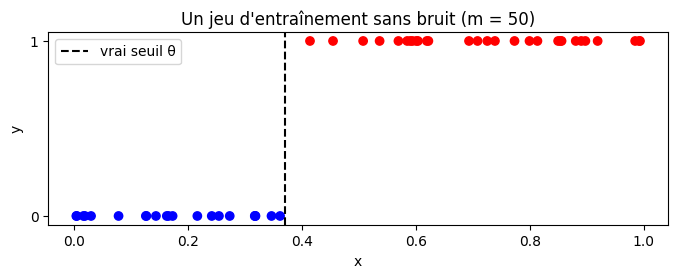

In [2]:
def generer_donnees(m, eta=0.0):
    # tirer m points au hasard entre 0 et 1
    x = rng.uniform(0, 1, m)

    # donner le bon label à chaque point
    y = np.zeros(m, dtype=int)          # tableau de m zéros (entiers)
    for i in range(m):
        if x[i] > THETA:
            y[i] = 1                    # à droite du seuil : label 1
        else:
            y[i] = 0                    # à gauche du seuil : label 0

    # inverser certains labels (chacun avec une probabilité eta)
    tirages = rng.random(m)             # m nombres au hasard entre 0 et 1
    for i in range(m):
        if tirages[i] < eta:            # arrive avec une probabilité eta
            y[i] = 1 - y[i]             # 0 devient 1, 1 devient 0

    return x, y

# Un jeu d'entraînement par taille demandée
for m in M_VALUES:
    x, y = generer_donnees(m)
    print(f"m = {m:3d} : {y.sum()} labels à 1, {m - y.sum()} labels à 0")

# Affichage d'un jeu (m = 50)
x, y = generer_donnees(50)
plt.figure(figsize=(8, 2.5))
plt.scatter(x, y, c=y, cmap="bwr")
plt.axvline(THETA, color="k", ls="--", label="vrai seuil θ")
plt.xlabel("x"); plt.ylabel("y"); plt.yticks([0, 1]); plt.legend()
plt.title("Un jeu d'entraînement sans bruit (m = 50)")
plt.show()

Tous les points à gauche de $\theta$ ont le label 0, tous ceux à droite ont le label 1.

## 2. L'algorithme ERM

ERM (minimisation du risque empirique) choisit le seuil qui fait le moins d'erreurs sur les exemples d'entraînement.

On ne peut pas tester tous les seuils possibles, il y en a une infinité. Mais l'erreur ne change que quand le seuil passe un point : entre deux points voisins, tous les seuils classent les exemples de la même façon. Il suffit donc d'essayer de couper juste après chaque point (plus le cas « avant tous les points ») et de garder la coupure qui fait le moins d'erreurs.

Une fois la meilleure coupure trouvée, on sait que le bon seuil est quelque part dans le trou entre ce point et le point suivant, puisque tout ce trou donne la même erreur. On renvoie le milieu de ce trou. Ça ne change pas l'erreur d'entraînement, mais le seuil est mieux placé pour les nouveaux points, car il reste loin des deux exemples les plus proches.

On trie les points au début uniquement pour retrouver facilement le point suivant.

In [3]:
def erm(x, y):
    xs = np.sort(x)                               # x trié, juste pour trouver le voisin
    meilleur_i = -1                               # -1 = couper avant tous les points
    meilleure_err = np.mean((x > 0).astype(int) != y)
    for i in range(len(xs)):                      # on essaie de couper sur chaque point
        err = np.mean((x > xs[i]).astype(int) != y)
        if err < meilleure_err:
            meilleur_i = i                        # on retient la pos dans xs
            meilleure_err = err

    # bord gauche du trou : le point où on coupe (ou 0)
    if meilleur_i == -1:
        gauche = 0.0
    else:
        gauche = xs[meilleur_i]
    # bord droit du trou : la case d'après dans xs (ou 1)
    if meilleur_i + 1 < len(xs):
        droite = xs[meilleur_i + 1]
    else:
        droite = 1.0
    return (gauche + droite) / 2, meilleure_err

## 3. Erreur empirique et erreur vraie

L'erreur empirique $L_S$ est le taux d'erreur sur les exemples d'entraînement. L'erreur vraie $L_D$ est le taux d'erreur sur de nouveaux exemples. On l'estime avec un grand jeu de test de 100 000 points, tiré de la même façon mais indépendamment.

In [4]:
x_test, y_test = generer_donnees(N_TEST)   # jeu de test sans bruit

def erreur_vraie(t, x_test, y_test):
    return np.mean((x_test > t).astype(int) != y_test)

print("   m | seuil appris | erreur empirique | erreur vraie")
for m in M_VALUES:
    x, y = generer_donnees(m)
    t, err_emp = erm(x, y)
    print(f"{m:4d} | {t:12.3f} | {err_emp:16.3f} | {erreur_vraie(t, x_test, y_test):12.3f}")

   m | seuil appris | erreur empirique | erreur vraie
   5 |        0.341 |            0.000 |        0.030
  10 |        0.423 |            0.000 |        0.053
  20 |        0.384 |            0.000 |        0.013
  50 |        0.345 |            0.000 |        0.025
 100 |        0.368 |            0.000 |        0.001
 200 |        0.374 |            0.000 |        0.004


L'erreur empirique vaut toujours 0 : sans bruit, le vrai seuil explique parfaitement les exemples, donc ERM trouve toujours un seuil sans erreur. L'erreur vraie, elle, n'est pas nulle, parce que l'algorithme ne connaît $\theta$ qu'approximativement. Elle a tendance à diminuer quand $m$ augmente, mais avec un seul essai par taille les valeurs sautent un peu (un échantillon peut être malchanceux). C'est pour ça qu'on répète l'expérience 1000 fois dans la partie suivante.

## 4. Vérification du PAC

Le cadre PAC dit : avec assez d'exemples, la probabilité que l'erreur vraie dépasse $\varepsilon$ devient aussi petite qu'on veut.

Pour le vérifier, pour chaque $m$ on refait l'expérience 1000 fois et on compte la proportion d'essais où l'erreur vraie dépasse $\varepsilon = 0{,}05$.

m =   5 : Pr(erreur vraie > 0.05) = 0.571
m =  10 : Pr(erreur vraie > 0.05) = 0.352
m =  20 : Pr(erreur vraie > 0.05) = 0.119
m =  50 : Pr(erreur vraie > 0.05) = 0.008
m = 100 : Pr(erreur vraie > 0.05) = 0.000
m = 200 : Pr(erreur vraie > 0.05) = 0.000


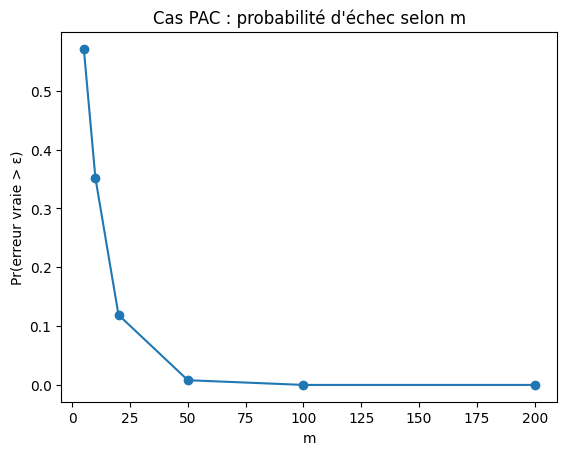

In [5]:
def proba_echec(m, eta, x_test, y_test, seuil_echec):
    # proportion des essais où l'erreur vraie dépasse seuil_echec
    echecs = 0
    for _ in range(N_REPS):
        x, y = generer_donnees(m, eta)
        t, _ = erm(x, y)
        if erreur_vraie(t, x_test, y_test) > seuil_echec:
            echecs += 1
    return echecs / N_REPS

p_pac = [proba_echec(m, 0.0, x_test, y_test, EPS) for m in M_VALUES]
for m, p in zip(M_VALUES, p_pac):
    print(f"m = {m:3d} : Pr(erreur vraie > {EPS}) = {p:.3f}")

plt.plot(M_VALUES, p_pac, "o-")
plt.xlabel("m"); plt.ylabel("Pr(erreur vraie > ε)")
plt.title("Cas PAC : probabilité d'échec selon m")
plt.show()

La probabilité d'échec baisse très vite quand $m$ augmente et devient nulle à partir de $m = 100$. C'est exactement ce que promet le cadre PAC : plus on a d'exemples, plus on est sûr d'avoir un bon classifieur.

## 5. Cas agnostique : on ajoute du bruit

Maintenant 10 % des labels sont faux, dans les données d'entraînement comme dans le jeu de test. Même le vrai seuil $\theta$ se trompe sur environ 10 % des points, donc la meilleure erreur vraie possible est $\eta = 0{,}1$. On ne peut plus demander une erreur inférieure à $\varepsilon = 0{,}05$. On demande à la place une erreur inférieure à $\eta + \varepsilon = 0{,}15$ : « presque aussi bien que le meilleur seuil possible ».

   m | erreur empirique | erreur vraie
   5 |            0.000 |        0.143
  10 |            0.100 |        0.176
  20 |            0.050 |        0.296
  50 |            0.080 |        0.127
 100 |            0.120 |        0.104
 200 |            0.090 |        0.103

m =   5 : Pr(erreur vraie > 0.15) = 0.631
m =  10 : Pr(erreur vraie > 0.15) = 0.393
m =  20 : Pr(erreur vraie > 0.15) = 0.216
m =  50 : Pr(erreur vraie > 0.15) = 0.056
m = 100 : Pr(erreur vraie > 0.15) = 0.006
m = 200 : Pr(erreur vraie > 0.15) = 0.000


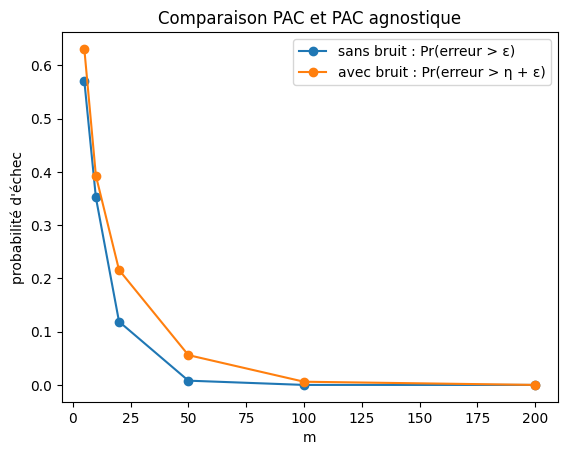

In [6]:
x_test_b, y_test_b = generer_donnees(N_TEST, ETA)   # jeu de test avec bruit

print("   m | erreur empirique | erreur vraie")
for m in M_VALUES:
    x, y = generer_donnees(m, ETA)
    t, err_emp = erm(x, y)
    print(f"{m:4d} | {err_emp:16.3f} | {erreur_vraie(t, x_test_b, y_test_b):12.3f}")

p_agn = [proba_echec(m, ETA, x_test_b, y_test_b, ETA + EPS) for m in M_VALUES]
print()
for m, p in zip(M_VALUES, p_agn):
    print(f"m = {m:3d} : Pr(erreur vraie > {ETA + EPS:.2f}) = {p:.3f}")

plt.plot(M_VALUES, p_pac, "o-", label="sans bruit : Pr(erreur > ε)")
plt.plot(M_VALUES, p_agn, "o-", label="avec bruit : Pr(erreur > η + ε)")
plt.xlabel("m"); plt.ylabel("probabilité d'échec"); plt.legend()
plt.title("Comparaison PAC et PAC agnostique")
plt.show()

L'erreur empirique peut-elle encore être nulle ? Seulement quand l'échantillon est petit et que, par chance, aucun label faux n'a été tiré. Avec plus d'exemples, il y a forcément des labels faux qu'aucun seuil ne peut expliquer, et l'erreur empirique tourne autour de 10 %.

Avoir plus d'exemples aide-t-il encore ? Oui, la probabilité d'échec diminue toujours avec $m$. Mais l'erreur vraie descend vers 10 % et pas vers 0, et la courbe avec bruit reste au-dessus de celle sans bruit : il faut plus d'exemples pour le même résultat.

Le lien avec le cours : dans le cadre PAC on peut viser une erreur presque nulle. Dans le cadre PAC agnostique c'est impossible, alors on vise une erreur proche de la meilleure possible dans la classe.

## 6. Conclusion

| | PAC (sans bruit) | PAC agnostique (avec bruit) |
|---|---|---|
| Erreur empirique | toujours 0 | rarement 0, environ $\eta$ quand $m$ est grand |
| Erreur vraie quand $m$ grandit | tend vers 0 | tend vers $\eta$ |
| Ce qu'on demande | erreur $\le \varepsilon$ | erreur $\le \eta + \varepsilon$ |

Dans les deux cas ERM apprend : plus on lui donne d'exemples, mieux il fait. La différence est que sans bruit on peut atteindre une erreur quasi nulle, alors qu'avec du bruit on peut seulement s'approcher de la meilleure erreur possible, et il faut plus de données pour y arriver.